# KGS · Notebook 1 — Mô hình định giá bất động sản (AVM)

Notebook này chạy lại **toàn bộ quy trình huấn luyện** mô hình định giá của KGS, từng bước một, rồi chỉ ra **mô hình được tích hợp vào hệ thống như thế nào** — từ lúc người dùng bấm "Định giá" tới lúc con số hiện trên màn hình.

Mã trong notebook chép nguyên logic từ thư mục `ml-service` của đồ án, nên kết quả khớp với mô hình đang chạy thật:

| Bước | Nội dung | Tệp tương ứng trong đồ án |
|---|---|---|
| 0 | Cài đặt, cấu hình | `ml-service/requirements.txt` |
| 1 | Tải dữ liệu thô từ HuggingFace | `training/prepare_data.py` |
| 2 | Chuẩn hoá tên hành chính | `app/normalize.py` |
| 3 | Làm sạch và bỏ tin trùng | `app/features.py` · `clean()` |
| 4 | Khám phá dữ liệu | — |
| 5 | Dựng 15 đặc trưng | `app/features.py` · `build_features()` |
| 6 | Chia tập theo thời gian | `training/train.py` · `time_split()` |
| 7 | Ba mô hình nền | `training/baselines.py` |
| 8 | Huấn luyện LightGBM, theo dõi từng giai đoạn | `training/train.py` · `train_gbm()` |
| 9 | Đánh giá và so sánh, phân tích sai số | `app/metrics.py` |
| 10 | Mức đóng góp của đặc trưng | `training/train.py` |
| 11 | Hiệu chỉnh khoảng tin cậy (split conformal) | `training/calibrate_interval.py` |
| 12 | Lưu mô hình | `models/avm.*` |
| 13 | Phục vụ dự đoán | `app/predict.py` |
| 14 | Tích hợp vào hệ thống: luồng từ người dùng | `app/main.py`, `ValuationService.cs`, `dinh-gia.tsx` |

**Thời gian chạy trên Colab (CPU):** khoảng 10–20 phút, phần lớn là tải dữ liệu (~500 MB) và huấn luyện LightGBM. Muốn chạy nhanh để xem quy trình, đặt `QUICK = True` ở ô cấu hình — kết quả sẽ kém hơn một chút.

**Kết quả kỳ vọng** (mô hình đang phục vụ, huấn luyện 06/09/2026): MdAPE **17,4%**, PPE10 31,1%, PPE20 55,5% trên 95.532 tin kiểm tra; khoảng 80% sau hiệu chỉnh phủ 75–79%.

## Bước 0 — Cài đặt và cấu hình

Colab có sẵn pandas, numpy, scikit-learn, matplotlib. Chỉ cần cài đúng bản LightGBM mà dịch vụ dùng (4.5.0), và FastAPI để mô phỏng dịch vụ ở bước 14.

In [ ]:
# Colab đã có sẵn pandas, numpy, scikit-learn, scipy, matplotlib.
# Ghim LightGBM đúng bản dịch vụ KGS đang dùng để kết quả khớp với báo cáo.
%pip install -q lightgbm==4.5.0 fastapi httpx

In [2]:
import os, json, math, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import sklearn, joblib

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110

# ---- Cấu hình ----
N_SHARDS = 3          # bộ dữ liệu có 10 phần (shard); đồ án dùng 3 phần đầu ≈ 1 triệu dòng thô
QUICK = False         # True = huấn luyện tối đa 600 vòng để chạy nhanh (kết quả kém hơn một chút)
SEED = 42
DATA_DIR = Path(os.environ.get("KGS_DATA_DIR", "kgs_data"))
OUT_DIR = Path("kgs_models")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| lightgbm", lgb.__version__)

pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.5.2 | lightgbm 4.5.0


## Bước 1 — Tải dữ liệu thô

Nguồn: bộ [`tinixai/vietnam-real-estates`](https://huggingface.co/datasets/tinixai/vietnam-real-estates) trên HuggingFace — tin rao bất động sản Việt Nam, chia thành 10 tệp parquet. Đồ án dùng 3 tệp đầu: đủ lớn để học mặt bằng giá, mà vòng thử nghiệm chỉ mất vài phút.

Ngay khi nạp, tên cột được đổi về từ vựng của dự án (`district_name` → `district`…), để mọi bước sau chỉ thấy một bộ tên.

> **Giới hạn của nguồn:** bộ dữ liệu **chỉ có tin rao bán** (giá ở mức tỷ đồng), không có tin cho thuê. Vì vậy mô hình chỉ định giá được mảng mua bán.

In [3]:
# ==== Chuẩn hoá tên hành chính — chép từ ml-service/app/normalize.py ====
import re, unicodedata

_PREFIXES = ["thanh pho", "quan", "huyen", "thi xa", "thi tran", "phuong", "xa",
             "tp", "tx", "tt", "q", "h", "p"]
_MULTISPACE = re.compile(r"\s+")
_NON_ALNUM = re.compile(r"[^a-z0-9\s]")
_PROVINCE_ALIASES = {"hcm": "ho chi minh", "tphcm": "ho chi minh", "sai gon": "ho chi minh",
                     "hn": "ha noi", "dn": "da nang", "brvt": "ba ria vung tau"}

def strip_accents(text):
    """Bỏ dấu tiếng Việt bằng chuẩn hoá Unicode NFD; 'đ' phải thay tay."""
    if not text:
        return ""
    decomposed = unicodedata.normalize("NFD", text)
    stripped = "".join(c for c in decomposed if unicodedata.category(c) != "Mn")
    return unicodedata.normalize("NFC", stripped).replace("đ", "d").replace("Đ", "D")

def norm_key(value):
    """Đưa một địa danh về dạng khoá: chữ thường, không dấu, không tiền tố hành chính."""
    if not value:
        return ""
    text = strip_accents(str(value)).lower()
    text = _NON_ALNUM.sub(" ", text)
    text = _MULTISPACE.sub(" ", text).strip()
    changed = True
    while changed:                      # cắt tiền tố lặp lại: "tp thu duc" -> "thu duc"
        changed = False
        for prefix in _PREFIXES:
            if text == prefix:
                return ""
            if text.startswith(prefix + " "):
                text = text[len(prefix) + 1:].strip()
                changed = True
                break
    return text

def norm_province(value):
    key = norm_key(value)
    if key.startswith("tinh "):         # "Tỉnh Khánh Hòa" -> "khanh hoa"
        key = key[len("tinh "):].strip()
    return _PROVINCE_ALIASES.get(key, key)

def norm_district(value):
    return norm_key(value)

def norm_ward(value):
    return norm_key(value)

In [4]:
# ==== Đặc trưng — chép từ ml-service/app/features.py và app/timeparse.py ====
from dataclasses import dataclass

def parse_published(values):
    """Đọc thời gian đăng. format='ISO8601' đọc được cả dòng có và không có micro-giây."""
    return pd.to_datetime(values, format="ISO8601", utc=True, errors="coerce")

CATEGORICAL = ["property_type", "province", "district", "ward", "house_direction"]
NUMERIC = ["area", "log_area", "bedroom_count", "bathroom_count", "floor_count",
           "frontage_width", "house_depth", "road_width", "area_per_bedroom", "published_month"]
FEATURES = CATEGORICAL + NUMERIC

@dataclass(frozen=True)
class Bounds:
    min_price: float = 100_000_000          # 100 triệu
    max_price: float = 200_000_000_000      # 200 tỷ
    min_area: float = 10.0
    max_area: float = 2_000.0
    min_price_per_m2: float = 1_000_000     # 1 triệu/m²
    max_price_per_m2: float = 800_000_000   # 800 triệu/m²

DEFAULT_BOUNDS = Bounds()

def clean(df, bounds=DEFAULT_BOUNDS):
    """Lọc rác: giá, diện tích, giá mỗi m², thiếu tỉnh/quận."""
    price = pd.to_numeric(df["price"], errors="coerce")
    area = pd.to_numeric(df["area"], errors="coerce")
    with np.errstate(divide="ignore", invalid="ignore"):
        ppm2 = price / area
    keep = (price.between(bounds.min_price, bounds.max_price)
            & area.between(bounds.min_area, bounds.max_area)
            & ppm2.between(bounds.min_price_per_m2, bounds.max_price_per_m2)
            & df["province"].notna() & df["district"].notna())
    return df.loc[keep].copy()

def build_features(df):
    """Dựng 15 đặc trưng. Hàm này dùng chung cho lúc huấn luyện VÀ lúc phục vụ dự đoán."""
    out = pd.DataFrame(index=df.index)
    out["property_type"] = df["property_type"].fillna("").astype(str).str.strip().str.lower()
    out["province"] = df["province"].map(norm_province)
    out["district"] = df["district"].map(norm_district)
    out["ward"] = df["ward"].map(norm_ward)
    out["house_direction"] = (df.get("house_direction", pd.Series(index=df.index, dtype=object))
                              .fillna("").astype(str).str.strip().str.lower())
    area = pd.to_numeric(df["area"], errors="coerce")
    out["area"] = area
    out["log_area"] = np.log1p(area.clip(lower=0))
    for col in ["bedroom_count", "bathroom_count", "floor_count",
                "frontage_width", "house_depth", "road_width"]:
        out[col] = pd.to_numeric(df.get(col), errors="coerce")
    with np.errstate(divide="ignore", invalid="ignore"):
        out["area_per_bedroom"] = area / out["bedroom_count"].replace(0, np.nan)
    published = parse_published(df.get("published_at"))
    out["published_month"] = ((published.dt.year - 2020) * 12 + published.dt.month).astype("float64")
    return out

def to_categorical(df, categories=None):
    """Ép cột phân loại về 'category'. Lúc phục vụ PHẢI dùng lại đúng tập hạng mục lúc train."""
    out = df.copy()
    for col in CATEGORICAL:
        if categories is not None:
            out[col] = pd.Categorical(out[col], categories=categories[col])
        else:
            out[col] = out[col].astype("category")
    return out

def category_map(df):
    return {col: list(df[col].cat.categories) for col in CATEGORICAL}

In [5]:
# ==== Tải dữ liệu — tương ứng ml-service/training/prepare_data.py ====
import requests

BASE_URL = "https://huggingface.co/api/datasets/tinixai/vietnam-real-estates/parquet/default/train"
COLUMN_MAP = {
    "property_type_name": "property_type", "province_name": "province",
    "district_name": "district", "ward_name": "ward", "street_name": "street",
    "project_name": "project", "house_direction": "house_direction",
    "balcony_direction": "balcony_direction", "price": "price", "area": "area",
    "floor_count": "floor_count", "frontage_width": "frontage_width",
    "house_depth": "house_depth", "road_width": "road_width",
    "bedroom_count": "bedroom_count", "bathroom_count": "bathroom_count",
    "published_at": "published_at", "name": "title",
}

def download_shard(i):
    """Tải một shard parquet về đĩa (bỏ qua nếu đã có) — chạy lại notebook không phải tải lại."""
    path = DATA_DIR / f"shard_{i}.parquet"
    if not path.exists():
        print(f"  tải shard {i} …", flush=True)
        with requests.get(f"{BASE_URL}/{i}.parquet", stream=True, timeout=120) as r:
            r.raise_for_status()
            tmp = path.with_suffix(".part")
            with open(tmp, "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
            tmp.rename(path)
    return path

def load_raw(n_shards):
    frames = []
    for i in range(n_shards):
        df = pd.read_parquet(download_shard(i), columns=list(COLUMN_MAP.keys()))
        frames.append(df.rename(columns=COLUMN_MAP))
        print(f"  shard {i}: {len(df):,} dòng")
    return pd.concat(frames, ignore_index=True)

def prepare(raw):
    """Làm sạch + bỏ tin trùng, đúng thứ tự của prepare_data.py."""
    df = raw.copy()
    df["province_key"] = df["province"].map(norm_province)
    df = clean(df, DEFAULT_BOUNDS)
    df = df.drop_duplicates(subset=["province", "district", "ward", "street",
                                    "area", "price", "bedroom_count"])
    return df

In [6]:
t0 = time.time()
raw = load_raw(N_SHARDS)
print(f"\nTổng dữ liệu thô: {len(raw):,} dòng × {raw.shape[1]} cột  ({time.time() - t0:.0f} giây)")
raw.head(3)

  shard 0: 350,075 dòng


  shard 1: 350,075 dòng


  shard 2: 350,075 dòng

Tổng dữ liệu thô: 1,050,225 dòng × 18 cột  (2 giây)


,property_type,province,district,ward,street,project,house_direction,balcony_direction,price,area,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count,published_at,title
0,Nhà,Hà Nội,Bắc Từ Liêm,Phúc Diễn,Ngọa Long,None,None,None,7450000000,37.0,NaN,NaN,NaN,NaN,4.0,5.0,2025-06-01T05:12:56.941000,"Bán nhanh nhà 6 tầng thang máy, ngoạ long cầu ..."
1,Nhà,Hồ Chí Minh,8,5,Tạ Quang Bửu,None,None,None,9100000000,48.0,4.0,4.0,NaN,NaN,3.0,3.0,2025-06-06T04:37:25.903000,Bán gấp nhà mặt tiền 4 tầng khu phân lô Tạ Qua...
2,Biệt thự/Nhà liền kề,Vĩnh Long,Bình Minh,None,None,None,None,None,20000000000,300.0,NaN,NaN,NaN,NaN,NaN,NaN,2025-06-15T18:58:07.455000,"Bán biệt thự 300m2 gần sân bóng Bình Minh, đườ..."


In [7]:
# Mỗi cột thiếu bao nhiêu? Ô trống là đặc điểm thật của tin rao — người đăng hay bỏ qua.
def missing_rate(s):
    if s.dtype == object:
        return (s.isna() | s.astype(str).str.strip().isin(["", "nan", "None"])).mean()
    return s.isna().mean()

miss = pd.Series({c: missing_rate(raw[c]) for c in raw.columns}).sort_values()
(miss * 100).round(1).to_frame("% ô trống (dữ liệu thô)")

,% ô trống (dữ liệu thô)
property_type,0.0
province,0.0
published_at,0.0
area,0.0
title,0.0
district,2.3
price,6.8
ward,14.4
street,39.9
frontage_width,45.8


## Bước 2 — Chuẩn hoá tên hành chính

Đây là mảnh ghép quyết định và không hiển nhiên. Bộ dữ liệu ghi quận là `"8"`, `"Tân Phú"`; nền tảng KGS ghi `"Quận 8"`, `"Quận Tân Phú"`, `"TP. Thủ Đức"`. Nếu không quy về một dạng, mô hình học đặc trưng `"8"` sẽ không bao giờ khớp với tin mang quận `"Quận 8"` — mô hình vẫn trả về số, chỉ là mọi tin thật rơi vào nhánh "quận lạ". **Không lỗi, không log, chỉ sai lặng lẽ.** Phần này có 34 ca kiểm thử trong `ml-service/tests/test_normalize.py`.

Quy tắc: mọi thứ về dạng khoá — chữ thường, không dấu, không tiền tố đơn vị hành chính.

In [8]:
examples = [
    ("tỉnh", "TP. Hồ Chí Minh"), ("tỉnh", "Hồ Chí Minh"), ("tỉnh", "HCM"), ("tỉnh", "Tỉnh Khánh Hòa"),
    ("quận", "Quận 8"), ("quận", "Q.8"), ("quận", "8"), ("quận", "TP. Thủ Đức"),
    ("quận", "Quận Bình Thạnh"), ("quận", "Huyện Tịnh Biên"), ("phường", "Phường 12"),
]
pd.DataFrame([{"loại": k, "giá trị gốc": v,
               "khoá sau chuẩn hoá": norm_province(v) if k == "tỉnh" else norm_key(v)}
              for k, v in examples])

,loại,giá trị gốc,khoá sau chuẩn hoá
0,tỉnh,TP. Hồ Chí Minh,ho chi minh
1,tỉnh,Hồ Chí Minh,ho chi minh
2,tỉnh,HCM,ho chi minh
3,tỉnh,Tỉnh Khánh Hòa,khanh hoa
4,quận,Quận 8,8
5,quận,Q.8,8
6,quận,8,8
7,quận,TP. Thủ Đức,thu duc
8,quận,Quận Bình Thạnh,binh thanh
9,quận,Huyện Tịnh Biên,tinh bien


In [9]:
# Hiệu quả trên dữ liệu thật: số cách viết khác nhau trước và sau chuẩn hoá
for col, fn in [("province", norm_province), ("district", norm_district)]:
    before = raw[col].dropna().nunique()
    after = raw[col].dropna().map(fn).nunique()
    print(f"{col:<9}: {before:>5,} cách viết  →  {after:>5,} khoá")

province :    63 cách viết  →     63 khoá


district :   588 cách viết  →    584 khoá


## Bước 3 — Làm sạch và bỏ tin trùng

Số liệu tin rao có nhiều rác: giá 1 đồng, diện tích 99.999 m², gõ thừa một số 0. Một giá trị sai kiểu đó kéo lệch mô hình mạnh hơn nhiều so với việc mất vài dòng tốt.

| Quy tắc | Ngưỡng | Vì sao |
|---|---|---|
| Giá | 100 triệu – 200 tỷ | dưới là lỗi nhập; trên là bất động sản thương mại |
| Diện tích | 10 – 2.000 m² | loại lỗi gõ |
| Giá mỗi m² | 1 – 800 triệu/m² | 20 tỷ là bình thường với 300 m² nhưng là lỗi với 25 m² — chỉ chặn giá tuyệt đối thì bỏ lọt |
| Bỏ tin trùng | trùng tỉnh, quận, phường, đường, diện tích, giá, số phòng ngủ | tin đăng lại nhiều lần sẽ lọt vào cả tập học lẫn tập kiểm tra → "đoán đúng" chỉ vì đã thấy |

Ô dưới áp từng quy tắc **lần lượt** để thấy mỗi bước loại bao nhiêu dòng.

In [10]:
b = DEFAULT_BOUNDS
price = pd.to_numeric(raw["price"], errors="coerce")
area = pd.to_numeric(raw["area"], errors="coerce")
with np.errstate(divide="ignore", invalid="ignore"):
    ppm2 = price / area

steps = [
    ("Dữ liệu thô", pd.Series(True, index=raw.index)),
    ("Giá trong 100 triệu – 200 tỷ", price.between(b.min_price, b.max_price)),
    ("Diện tích trong 10 – 2.000 m²", area.between(b.min_area, b.max_area)),
    ("Giá/m² trong 1 – 800 triệu", ppm2.between(b.min_price_per_m2, b.max_price_per_m2)),
    ("Có tỉnh và quận", raw["province"].notna() & raw["district"].notna()),
]
mask = pd.Series(True, index=raw.index)
rows = []
for name, m in steps:
    prev = int(mask.sum())
    mask &= m
    rows.append({"bước": name, "còn lại": int(mask.sum()), "bị loại": prev - int(mask.sum())})

df = prepare(raw)        # đúng hàm của prepare_data.py: clean() rồi bỏ trùng
rows.append({"bước": "Bỏ tin trùng", "còn lại": len(df), "bị loại": rows[-1]["còn lại"] - len(df)})
funnel = pd.DataFrame(rows)
funnel["% còn lại so với thô"] = (funnel["còn lại"] / len(raw) * 100).round(1)
print(f"Sau làm sạch: {len(df):,} tin  (báo cáo đồ án: 637.598)")
funnel

Sau làm sạch: 637,598 tin  (báo cáo đồ án: 637.598)


,bước,còn lại,bị loại,% còn lại so với thô
0,Dữ liệu thô,1050225,0,100.0
1,Giá trong 100 triệu – 200 tỷ,973213,77012,92.7
2,Diện tích trong 10 – 2.000 m²,963212,10001,91.7
3,Giá/m² trong 1 – 800 triệu,958310,4902,91.2
4,Có tỉnh và quận,936600,21710,89.2
5,Bỏ tin trùng,637598,299002,60.7


In [11]:
dup_share = funnel.iloc[-1]["bị loại"] / funnel.iloc[-2]["còn lại"] * 100
print(f"Tin trùng chiếm {dup_share:.1f}% số dòng đã qua bộ lọc giá trị.")
del raw   # giải phóng RAM trên Colab

Tin trùng chiếm 31.9% số dòng đã qua bộ lọc giá trị.


## Bước 4 — Khám phá dữ liệu sau làm sạch

Mục đích: biết mô hình học trên dữ liệu như thế nào — phân bố theo tỉnh, loại hình, mức giá, thời gian đăng và mức độ thiếu thông tin.

In [12]:
ts_all = parse_published(df["published_at"])
print(f"Thời gian đăng: {ts_all.min():%d/%m/%Y} → {ts_all.max():%d/%m/%Y}")
print(f"Số tỉnh/thành: {df['province_key'].nunique()}")
p = pd.to_numeric(df["price"]) / 1e9
a = pd.to_numeric(df["area"])
print(f"Giá: trung vị {p.median():.2f} tỷ · 80% số tin nằm trong {p.quantile(.1):.1f}–{p.quantile(.9):.1f} tỷ")
print(f"Diện tích: trung vị {a.median():.0f} m²")

pd.concat([
    df["province_key"].value_counts().head(8).rename("số tin").to_frame().reset_index(names="tỉnh (khoá)"),
    df["property_type"].value_counts().head(8).rename("số tin ").to_frame().reset_index(names="loại hình"),
], axis=1)

Thời gian đăng: 01/06/2025 → 29/09/2025
Số tỉnh/thành: 63


Giá: trung vị 7.48 tỷ · 80% số tin nằm trong 2.0–29.5 tỷ
Diện tích: trung vị 80 m²


,tỉnh (khoá),số tin,loại hình,số tin
0,ha noi,242047,Nhà,317703.0
1,ho chi minh,207917,Đất,150192.0
2,da nang,35734,Căn hộ chung cư,114952.0
3,binh duong,26666,Biệt thự/Nhà liền kề,44636.0
4,khanh hoa,18331,Shophouse,10115.0
5,hai phong,14443,NaN,NaN
6,dong nai,10673,NaN,NaN
7,hung yen,10500,NaN,NaN


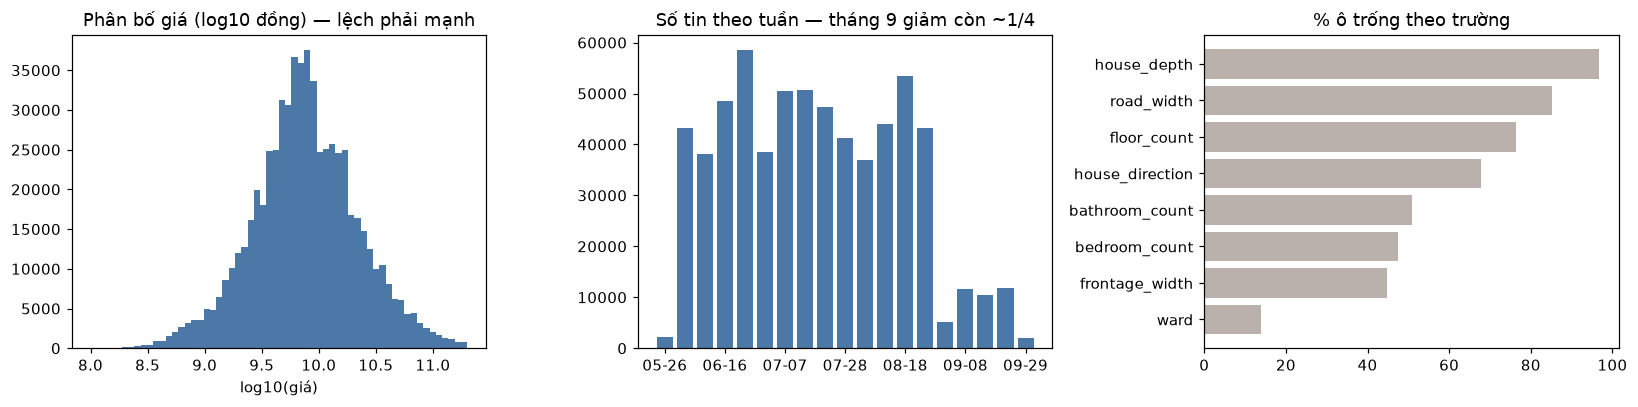

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

axes[0].hist(np.log10(pd.to_numeric(df["price"])), bins=60, color="#4C78A8")
axes[0].set_title("Phân bố giá (log10 đồng) — lệch phải mạnh")
axes[0].set_xlabel("log10(giá)")

weekly = ts_all.dt.tz_convert(None).dt.to_period("W").value_counts().sort_index()
axes[1].bar(range(len(weekly)), weekly.values, color="#4C78A8")
axes[1].set_xticks(range(0, len(weekly), 3), [str(w.start_time.date())[5:] for w in weekly.index[::3]])
axes[1].set_title("Số tin theo tuần — tháng 9 giảm còn ~1/4")

m2 = pd.Series({c: missing_rate(df[c]) * 100 for c in
                ["bedroom_count", "bathroom_count", "floor_count", "frontage_width",
                 "house_depth", "road_width", "house_direction", "ward"]}).sort_values()
axes[2].barh(m2.index, m2.values, color="#BAB0AC")
axes[2].set_title("% ô trống theo trường")
plt.tight_layout(); plt.show()

**Đọc biểu đồ:** giá trải từ vài trăm triệu tới hàng trăm tỷ nên mô hình sẽ học trên **log(giá)**. Nhiều trường rất hay bị bỏ trống (chiều sâu, đường trước nhà, số tầng) — mô hình phải chịu được ô trống, và **không được điền bừa**: "không khai số tầng" là một thông tin thật về tin rao.

## Bước 5 — Dựng 15 đặc trưng

| Loại | Đặc trưng | Ghi chú |
|---|---|---|
| Phân loại (5) | loại hình, tỉnh, quận, phường, hướng nhà | LightGBM xử lý trực tiếp kiểu `category`, không cần one-hot |
| Số (10) | diện tích, log(diện tích), phòng ngủ, phòng tắm, số tầng, mặt tiền, chiều sâu, đường trước nhà, diện tích mỗi phòng ngủ, tháng đăng | ô trống giữ nguyên là NaN |

Hàm `build_features()` được dùng **ở cả lúc huấn luyện lẫn lúc phục vụ dự đoán**. Không có hai bản cài đặt thì không có lệch giữa train và serve (*training/serving skew*) — lỗi kinh điển và khó thấy nhất của hệ thống ML.

**Mục tiêu học** là `log(giá)` chứ không phải giá: trên thang log, sai số trở thành sai số **tương đối** — sai 500 triệu ở căn 1 tỷ nặng hơn hẳn sai 500 triệu ở căn 50 tỷ, đúng như người dùng cảm nhận.

In [14]:
sample = build_features(df.head(5))
sample

,property_type,province,district,ward,house_direction,area,log_area,bedroom_count,bathroom_count,floor_count,frontage_width,house_depth,road_width,area_per_bedroom,published_month
0,nhà,ha noi,bac tu liem,phuc dien,,37.0,3.637586,4.0,5.0,NaN,NaN,NaN,NaN,9.25,66.0
1,nhà,ho chi minh,8,5,,48.0,3.891820,3.0,3.0,4.0,4.0,NaN,NaN,16.00,66.0
2,biệt thự/nhà liền kề,vinh long,binh minh,,,300.0,5.707110,NaN,NaN,NaN,NaN,NaN,NaN,NaN,66.0
3,căn hộ chung cư,ho chi minh,12,dong hung thuan,,44.0,3.806662,1.0,1.0,NaN,NaN,NaN,NaN,44.00,66.0
4,nhà,ho chi minh,tan phu,tan thanh,,60.0,4.110874,2.0,3.0,NaN,NaN,NaN,NaN,30.00,66.0


## Bước 6 — Chia tập theo THỜI GIAN, không ngẫu nhiên

Đây là quyết định quan trọng nhất của quy trình. Chia ngẫu nhiên cho mô hình nhìn thấy tin tháng 9 khi đoán tin tháng 6 — biết trước tương lai — nên độ đo đẹp hơn thực tế và không tái hiện được khi triển khai.

- **Tập kiểm tra** = 15% tin **mới nhất** (sau mốc thời gian). Chỉ dùng để báo cáo kết quả.
- Phần còn lại tách tiếp **10% cuối** làm **tập kiểm định**: dùng để dừng sớm và hiệu chỉnh khoảng tin cậy. Dùng chính tập kiểm tra cho việc này là tự rò rỉ.
- **Tập học** = phần còn lại.

In [15]:
TEST_FRACTION = 0.15

def time_split(df, frac=TEST_FRACTION):
    """Cắt theo mốc thời gian: phần cũ để học, phần mới nhất để kiểm tra (train.py)."""
    ts = parse_published(df["published_at"])
    df = df.loc[ts.notna()].copy()
    ts = ts.loc[df.index]
    cutoff = ts.quantile(1.0 - frac)
    return df.loc[ts <= cutoff], df.loc[ts > cutoff], cutoff

train_df, test_df, cutoff = time_split(df)
n_valid = max(1, int(len(train_df) * 0.1))
fit_df, valid_df = train_df.iloc[:-n_valid], train_df.iloc[-n_valid:]

def span(part):
    t = parse_published(part["published_at"])
    return f"{t.min():%d/%m/%Y} → {t.max():%d/%m/%Y}"

split_table = pd.DataFrame([
    {"tập": "Học (fit)", "số tin": len(fit_df), "thời gian": span(fit_df), "dùng để": "huấn luyện"},
    {"tập": "Kiểm định (valid)", "số tin": len(valid_df), "thời gian": span(valid_df), "dùng để": "dừng sớm + hiệu chỉnh khoảng"},
    {"tập": "Kiểm tra (test)", "số tin": len(test_df), "thời gian": span(test_df), "dùng để": "chỉ để báo cáo"},
])
print(f"Mốc chia: {cutoff:%d/%m/%Y %H:%M}")
split_table

Mốc chia: 22/08/2025 17:47


,tập,số tin,thời gian,dùng để
0,Học (fit),487763,01/06/2025 → 22/08/2025,huấn luyện
1,Kiểm định (valid),54195,01/08/2025 → 22/08/2025,dừng sớm + hiệu chỉnh khoảng
2,Kiểm tra (test),95640,22/08/2025 → 29/09/2025,chỉ để báo cáo


In [16]:
y_fit = fit_df["price"].to_numpy(dtype="float64")
y_valid = valid_df["price"].to_numpy(dtype="float64")
y_test = test_df["price"].to_numpy(dtype="float64")

X_fit_raw = build_features(fit_df)
X_valid_raw = build_features(valid_df)
X_test_raw = build_features(test_df)
print("Ma trận đặc trưng:", X_fit_raw.shape, X_valid_raw.shape, X_test_raw.shape)

Ma trận đặc trưng: (487763, 15) (54195, 15) (95640, 15)


> **Vì sao số tin mỗi tập lệch vài trăm so với báo cáo** (học 487.215 · kiểm định 54.134 · kiểm tra 95.532 — tổng 636.881)? Mô hình đang phục vụ được huấn luyện **trước** khi sửa lỗi đọc ngày đăng: bản cũ đọc ngày bằng `errors="coerce"` và lặng lẽ bỏ **717 tin** có ngày ghi không kèm micro-giây (xem `app/timeparse.py`). Notebook dùng bản đã sửa (`format="ISO8601"`) nên giữ đủ 637.598 tin. Kết quả chỉ chênh dưới 0,1 điểm phần trăm.

## Bước 7 — Ba mô hình nền và bộ độ đo

Một con số MdAPE chỉ có nghĩa khi đặt cạnh thứ mô hình phải vượt qua. Ba mốc, khó dần:

1. **Trung vị giá/m² toàn quốc × diện tích** — mốc sàn.
2. **Trung vị giá/m² theo quận × diện tích** — mốc *thật sự đáng ngại*: vị trí giải thích phần lớn giá, đây cũng là cách môi giới hay ước lượng.
3. **Hồi quy Ridge trên log(giá)** — "có học máy nhưng đơn giản nhất".

**Độ đo** (tính trên giá thật, đơn vị đồng):

- **APE** của một tin = |giá dự đoán − giá thật| / giá thật × 100%.
- **MdAPE** = trung vị của APE. Dùng trung vị vì vài tin rác còn sót đủ sức kéo trung bình đi.
- **PPE10 / PPE20** = % số tin có APE ≤ 10% / ≤ 20% — độ đo các nền tảng định giá công bố.
- **RMSLE** = sai số bình phương trên thang log, khớp với hàm mất mát lúc huấn luyện.

Không dùng RMSE trên giá tuyệt đối: nó bị vài căn trăm tỷ chi phối.

In [17]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

def evaluate(y_true, y_pred):
    """Bộ độ đo của app/metrics.py."""
    y_true = np.asarray(y_true, dtype="float64"); y_pred = np.asarray(y_pred, dtype="float64")
    ok = np.isfinite(y_true) & np.isfinite(y_pred) & (y_true > 0) & (y_pred > 0)
    y_true, y_pred = y_true[ok], y_pred[ok]
    ape = np.abs(y_pred - y_true) / y_true * 100
    return {
        "n": int(y_true.size),
        "MdAPE (%)": float(np.median(ape)),
        "PPE10 (%)": float(np.mean(ape <= 10) * 100),
        "PPE20 (%)": float(np.mean(ape <= 20) * 100),
        "RMSLE": float(np.sqrt(np.mean((np.log(y_pred) - np.log(y_true)) ** 2))),
        "sai số trung vị (tỷ)": float(np.median(np.abs(y_pred - y_true)) / 1e9),
    }

class GlobalMedianPPM2:
    name = "Nền 1 · Trung vị giá/m² toàn quốc"
    def fit(self, X, price):
        ppm2 = price / X["area"].to_numpy()
        self.ppm2_ = float(np.median(ppm2[np.isfinite(ppm2)])); return self
    def predict(self, X):
        return X["area"].to_numpy() * self.ppm2_

class DistrictMedianPPM2:
    name = "Nền 2 · Trung vị giá/m² theo quận"
    def fit(self, X, price):
        d = X[["province", "district"]].copy(); d["ppm2"] = price / X["area"].to_numpy()
        d = d[np.isfinite(d["ppm2"])]
        self.by_district_ = d.groupby(["province", "district"])["ppm2"].median()
        self.by_province_ = d.groupby("province")["ppm2"].median()
        self.global_ = float(d["ppm2"].median()); return self
    def predict(self, X):
        idx = pd.MultiIndex.from_arrays([X["province"], X["district"]])
        ppm2 = self.by_district_.reindex(idx).to_numpy()
        ppm2 = np.where(np.isnan(ppm2), self.by_province_.reindex(X["province"]).to_numpy(), ppm2)
        ppm2 = np.where(np.isnan(ppm2), self.global_, ppm2)     # quận lạ → tỉnh → toàn quốc
        return X["area"].to_numpy() * ppm2

class RidgeLogPrice:
    name = "Nền 3 · Hồi quy tuyến tính (Ridge)"
    CAT = [c for c in CATEGORICAL if c != "ward"]    # hàng nghìn phường làm ma trận phình to
    def fit(self, X, price):
        self.pipe_ = make_pipeline(
            ColumnTransformer([
                ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), self.CAT),
                ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC),
            ]),
            Ridge(alpha=1.0))
        self.pipe_.fit(X, np.log(price)); return self
    def predict(self, X):
        return np.exp(self.pipe_.predict(X))

results = {}
for cls in [GlobalMedianPPM2, DistrictMedianPPM2, RidgeLogPrice]:
    t0 = time.time()
    m = cls().fit(X_fit_raw, y_fit)
    results[cls.name] = evaluate(y_test, m.predict(X_test_raw))
    print(f"{cls.name:<38} xong trong {time.time() - t0:5.1f} giây")

pd.DataFrame(results).T.round(2)

Nền 1 · Trung vị giá/m² toàn quốc      xong trong   0.0 giây


Nền 2 · Trung vị giá/m² theo quận      xong trong   0.3 giây


Nền 3 · Hồi quy tuyến tính (Ridge)     xong trong   7.8 giây


,n,MdAPE (%),PPE10 (%),PPE20 (%),RMSLE,sai số trung vị (tỷ)
Nền 1 · Trung vị giá/m² toàn quốc,95640.0,56.70,7.98,16.11,1.10,4.66
Nền 2 · Trung vị giá/m² theo quận,95640.0,33.71,16.37,31.44,0.62,2.55
Nền 3 · Hồi quy tuyến tính (Ridge),95640.0,26.83,19.66,38.48,0.50,1.85


## Bước 8 — Huấn luyện LightGBM

**Vì sao Gradient Boosting (LightGBM)?** Dữ liệu dạng bảng, nhiều cột phân loại (hàng trăm quận, hàng nghìn phường), nhiều ô trống. Trên dạng dữ liệu này cây tăng cường gradient mạnh nhất, huấn luyện trong vài phút, và giải thích được bằng mức đóng góp của từng đặc trưng.

| Siêu tham số | Giá trị | Ý nghĩa |
|---|---|---|
| `learning_rate` | 0,05 | bước nhỏ, nhiều vòng |
| `num_leaves` | 96 | độ phức tạp mỗi cây |
| `min_data_in_leaf` | 40 | chống học thuộc |
| `feature_fraction` / `bagging_fraction` | 0,85 / 0,85 | giảm phương sai |
| `lambda_l2` | 1,0 | chính quy hoá |
| `cat_smooth` / `min_data_per_group` | 20 / 50 | không tách nhánh riêng cho quận/phường chỉ có vài chục tin |
| số vòng tối đa / dừng sớm | 3.000 / 100 | dừng khi tập kiểm định không cải thiện 100 vòng liền |

Tập hạng mục (danh sách quận, phường…) lấy từ tập học và **lưu kèm mô hình** — lúc phục vụ phải nạp lại đúng tập này, nếu không mã hạng mục lệch và "quận 1" lúc serve mang mã của "quận 12" lúc train.

In [18]:
X_fit = to_categorical(X_fit_raw)
cats = category_map(X_fit)
X_valid = to_categorical(X_valid_raw, cats)
X_test = to_categorical(X_test_raw, cats)
print({k: len(v) for k, v in cats.items()}, "← số hạng mục mỗi cột phân loại")

params = {
    "objective": "regression", "metric": "rmse", "learning_rate": 0.05,
    "num_leaves": 96, "min_data_in_leaf": 40, "feature_fraction": 0.85,
    "bagging_fraction": 0.85, "bagging_freq": 1, "lambda_l2": 1.0,
    "cat_smooth": 20, "min_data_per_group": 50,
    "verbosity": -1, "seed": SEED, "num_threads": 0,
}
NUM_ROUNDS = 600 if QUICK else 3000

ds_train = lgb.Dataset(X_fit[FEATURES], label=np.log(y_fit), categorical_feature=CATEGORICAL)
ds_valid = lgb.Dataset(X_valid[FEATURES], label=np.log(y_valid), reference=ds_train)

history = {}
t0 = time.time()
booster = lgb.train(
    params, ds_train, num_boost_round=NUM_ROUNDS,
    valid_sets=[ds_valid], valid_names=["valid"],
    callbacks=[lgb.early_stopping(100, verbose=False),
               lgb.log_evaluation(250),
               lgb.record_evaluation(history)],
)
train_secs = time.time() - t0
print(f"\nHuấn luyện xong trong {train_secs:.0f} giây · số vòng tốt nhất: {booster.best_iteration}")

{'property_type': 5, 'province': 63, 'district': 558, 'ward': 3043, 'house_direction': 13} ← số hạng mục mỗi cột phân loại


[250]	valid's rmse: 0.380516


[500]	valid's rmse: 0.375605


[750]	valid's rmse: 0.372867


[1000]	valid's rmse: 0.370642


...

[2250]	valid's rmse: 0.36474


[2500]	valid's rmse: 0.364085


[2750]	valid's rmse: 0.363416


[3000]	valid's rmse: 0.362855



Huấn luyện xong trong 107 giây · số vòng tốt nhất: 2999


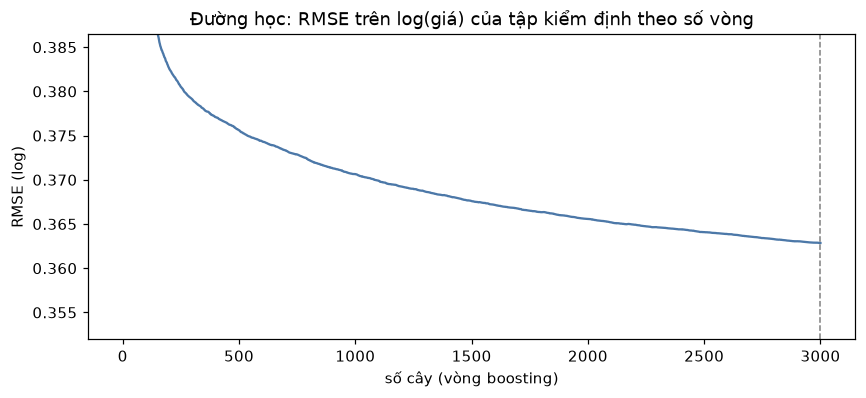

RMSE kiểm định: vòng 100 = 0.3935 · vòng 1000 = 0.3706 · cuối = 0.3629
Lưu ý: chưa dừng sớm — sai số kiểm định vẫn đang giảm khi chạm trần số vòng. Nâng trần có thể cải thiện thêm một chút (đã ghi là hướng phát triển).


In [19]:
curve = history["valid"]["rmse"]
plt.figure(figsize=(9, 3.6))
plt.plot(range(1, len(curve) + 1), curve, color="#4C78A8")
plt.axvline(booster.best_iteration, color="gray", ls="--", lw=1)
plt.ylim(min(curve) * 0.97, curve[min(150, len(curve) - 1)])
plt.title("Đường học: RMSE trên log(giá) của tập kiểm định theo số vòng")
plt.xlabel("số cây (vòng boosting)"); plt.ylabel("RMSE (log)")
plt.show()
print(f"RMSE kiểm định: vòng 100 = {curve[99]:.4f} · vòng 1000 = {curve[min(999, len(curve)-1)]:.4f} "
      f"· cuối = {curve[-1]:.4f}")
if booster.best_iteration > NUM_ROUNDS - 100:
    print("Lưu ý: chưa dừng sớm — sai số kiểm định vẫn đang giảm khi chạm trần số vòng. "
          "Nâng trần có thể cải thiện thêm một chút (đã ghi là hướng phát triển).")

### Kết quả theo từng giai đoạn huấn luyện

Mô hình boosting là tổng của nhiều cây nối tiếp nhau. Có thể "cắt" mô hình ở vòng thứ *k* để xem nếu chỉ dùng *k* cây đầu thì sai số trên **tập kiểm tra** là bao nhiêu — đây chính là kết quả qua từng giai đoạn huấn luyện.

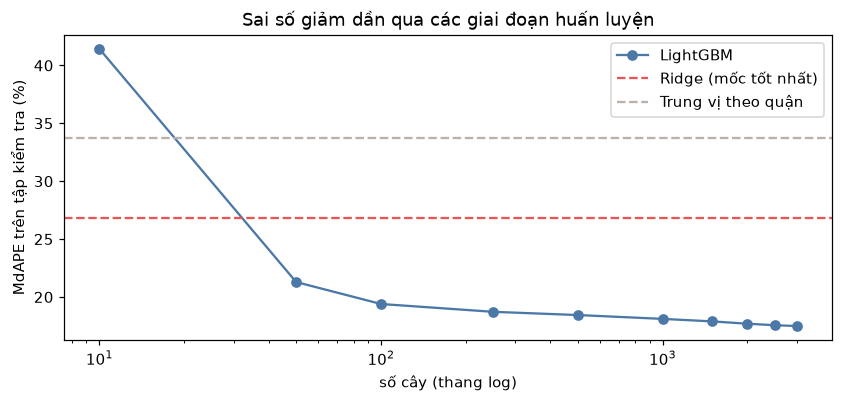

,MdAPE (%),PPE10 (%),PPE20 (%),RMSLE
số cây,,,,
10,41.44,13.58,25.97,0.74
50,21.29,25.64,47.50,0.43
100,19.39,27.93,51.25,0.39
250,18.72,29.02,52.69,0.38
500,18.44,29.46,53.35,0.38
1000,18.11,29.96,54.08,0.37
1500,17.89,30.33,54.62,0.37
2000,17.69,30.53,54.99,0.37
2500,17.56,30.73,55.27,0.37


In [20]:
stages = [k for k in [10, 50, 100, 250, 500, 1000, 1500, 2000, 2500] if k < booster.best_iteration] + [booster.best_iteration]
stage_rows = []
for k in stages:
    pred_k = np.exp(booster.predict(X_test[FEATURES], num_iteration=k))
    s = evaluate(y_test, pred_k)
    stage_rows.append({"số cây": k, **{c: s[c] for c in ["MdAPE (%)", "PPE10 (%)", "PPE20 (%)", "RMSLE"]}})
stage_table = pd.DataFrame(stage_rows).set_index("số cây")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(stage_table.index, stage_table["MdAPE (%)"], marker="o", color="#4C78A8", label="LightGBM")
ax.axhline(results["Nền 3 · Hồi quy tuyến tính (Ridge)"]["MdAPE (%)"], color="#E45756", ls="--", label="Ridge (mốc tốt nhất)")
ax.axhline(results["Nền 2 · Trung vị giá/m² theo quận"]["MdAPE (%)"], color="#BAB0AC", ls="--", label="Trung vị theo quận")
ax.set_xscale("log"); ax.set_xlabel("số cây (thang log)"); ax.set_ylabel("MdAPE trên tập kiểm tra (%)")
ax.set_title("Sai số giảm dần qua các giai đoạn huấn luyện"); ax.legend(); plt.show()
stage_table.round(2)

## Bước 9 — Đánh giá trên tập kiểm tra và so sánh

In [21]:
pred_test = np.exp(booster.predict(X_test[FEATURES], num_iteration=booster.best_iteration))
results["Gradient Boosting (LightGBM)"] = evaluate(y_test, pred_test)
compare = pd.DataFrame(results).T
best_base = compare.drop("Gradient Boosting (LightGBM)")["MdAPE (%)"].min()
gbm = compare.loc["Gradient Boosting (LightGBM)", "MdAPE (%)"]
print(f"LightGBM giảm MdAPE {(best_base - gbm) / best_base * 100:.1f}% so với mô hình nền tốt nhất "
      f"({best_base:.2f}% → {gbm:.2f}%).")
compare.round(2)

LightGBM giảm MdAPE 34.8% so với mô hình nền tốt nhất (26.83% → 17.49%).


,n,MdAPE (%),PPE10 (%),PPE20 (%),RMSLE,sai số trung vị (tỷ)
Nền 1 · Trung vị giá/m² toàn quốc,95640.0,56.70,7.98,16.11,1.10,4.66
Nền 2 · Trung vị giá/m² theo quận,95640.0,33.71,16.37,31.44,0.62,2.55
Nền 3 · Hồi quy tuyến tính (Ridge),95640.0,26.83,19.66,38.48,0.50,1.85
Gradient Boosting (LightGBM),95640.0,17.49,30.97,55.45,0.37,1.20


### Phân tích sai số: mô hình đúng ở đâu, sai ở đâu?

In [22]:
err = test_df[["province_key", "property_type"]].copy()
err["ape"] = np.abs(pred_test - y_test) / y_test * 100
err["price_bin"] = pd.qcut(y_test / 1e9, 5, labels=["20% rẻ nhất", "20–40%", "40–60%", "60–80%", "20% đắt nhất"])

def summarize(group):
    g = err.groupby(group, observed=True)["ape"]
    return pd.DataFrame({"số tin": g.size(), "MdAPE (%)": g.median().round(1),
                         "PPE20 (%)": g.apply(lambda s: (s <= 20).mean() * 100).round(1)})

display(summarize("property_type").sort_values("số tin", ascending=False).head(6))
display(summarize(err["province_key"].where(err["province_key"].isin(
    err["province_key"].value_counts().head(6).index), "tỉnh khác")).sort_values("số tin", ascending=False))
display(summarize("price_bin"))

,số tin,MdAPE (%),PPE20 (%)
property_type,,,
Nhà,47103,18.1,54.1
Đất,22874,22.5,45.4
Căn hộ chung cư,17494,12.4,70.6
Biệt thự/Nhà liền kề,6603,15.1,61.3
Shophouse,1566,19.9,50.2


,số tin,MdAPE (%),PPE20 (%)
province_key,,,
ha noi,34548,15.5,60.8
ho chi minh,31973,18.1,54.1
tỉnh khác,13633,22.0,46.2
da nang,5961,17.8,54.3
binh duong,4026,15.4,60.1
khanh hoa,3299,20.6,49.0
hai phong,2200,18.4,52.6


,số tin,MdAPE (%),PPE20 (%)
price_bin,,,
20% rẻ nhất,19631,19.9,50.2
20–40%,18660,14.3,63.6
40–60%,19742,14.5,64.0
60–80%,18518,18.3,53.9
20% đắt nhất,19089,22.2,45.6


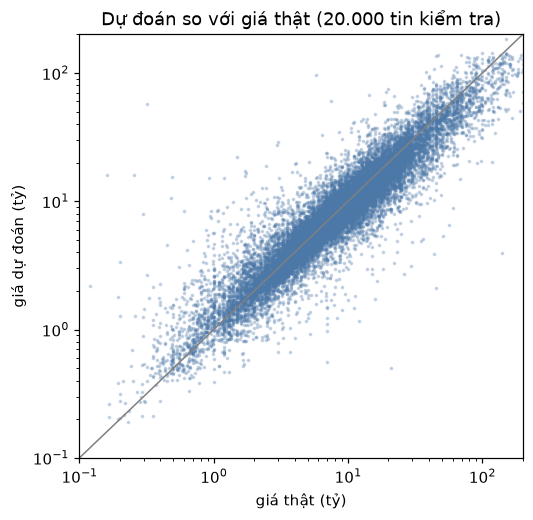

In [23]:
idx = np.random.default_rng(SEED).choice(len(y_test), size=min(20_000, len(y_test)), replace=False)
plt.figure(figsize=(5.2, 5))
plt.scatter(y_test[idx] / 1e9, pred_test[idx] / 1e9, s=2, alpha=0.25, color="#4C78A8")
lim = [0.1, 200]
plt.plot(lim, lim, color="gray", lw=1)
plt.xscale("log"); plt.yscale("log"); plt.xlim(lim); plt.ylim(lim)
plt.xlabel("giá thật (tỷ)"); plt.ylabel("giá dự đoán (tỷ)")
plt.title("Dự đoán so với giá thật (20.000 tin kiểm tra)"); plt.show()

## Bước 10 — Mức đóng góp của từng đặc trưng

"Gain" = tổng mức giảm hàm mất mát nhờ các lần tách cây trên đặc trưng đó. Đây là cách mô hình *giải thích được*: biết yếu tố nào quyết định giá.

Vị trí (quận, phường, tỉnh): 51.5%
Diện tích và biến thể: 29.9%


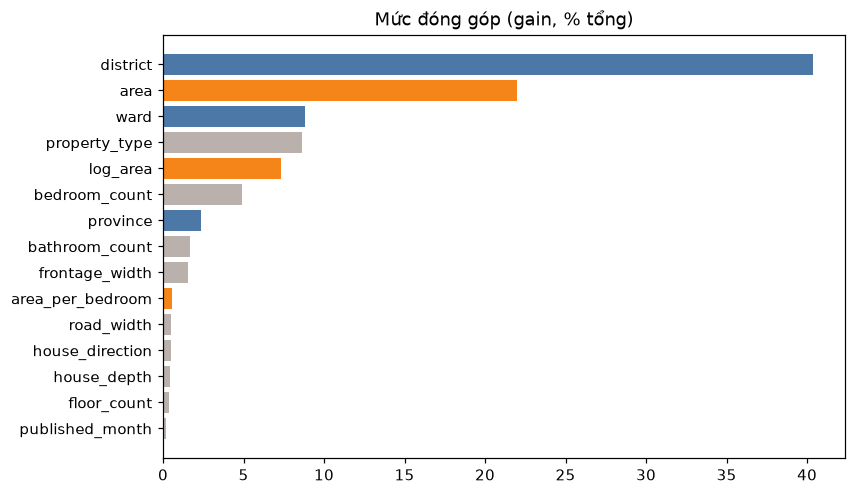

In [24]:
gains = pd.Series(booster.feature_importance("gain"), index=booster.feature_name()).sort_values()
gain_pct = gains / gains.sum() * 100
groups = {"Vị trí (quận, phường, tỉnh)": ["district", "ward", "province"],
          "Diện tích và biến thể": ["area", "log_area", "area_per_bedroom"]}
for g, cols in groups.items():
    print(f"{g}: {gain_pct[cols].sum():.1f}%")
color = ["#4C78A8" if c in groups["Vị trí (quận, phường, tỉnh)"] else
         "#F58518" if c in groups["Diện tích và biến thể"] else "#BAB0AC" for c in gain_pct.index]
plt.figure(figsize=(8, 5)); plt.barh(gain_pct.index, gain_pct.values, color=color)
plt.title("Mức đóng góp (gain, % tổng)"); plt.show()

## Bước 11 — Khoảng tin cậy: đo thay vì đoán (split conformal)

Một con số trần trụi "căn này 4,2 tỷ" là nguy hiểm: người đọc coi nó chính xác tới từng đồng. KGS luôn trả về **khoảng giá 80%** kèm **mức tin cậy**:

- **Thấp**: quận có dưới 30 tin trong dữ liệu học.
- **Trung bình**: khai ≤ 2 trong 4 trường tuỳ chọn (phòng ngủ, phòng tắm, số tầng, mặt tiền).
- **Cao**: còn lại.

Bản đầu đặt tay độ rộng ±12% / ±20% / ±32% trên thang log. Ô dưới **đo** xem "khoảng 80%" đó thực sự chứa giá thật bao nhiêu lần, rồi sửa bằng **split conformal**:

1. Trên tập kiểm định, tính phần dư r = |ln(giá thật) − ln(giá dự đoán)|.
2. Độ rộng q của mỗi mức = phân vị thứ ⌈(n+1)·0,8⌉/n của phần dư. Định lý conformal bảo đảm độ phủ ≥ 80% trên dữ liệu cùng phân phối, không cần giả định sai số chuẩn.
3. Khoảng = [giá·e^(−q), giá·e^(+q)] — bất đối xứng, đúng thực tế vì giá không âm.
4. **Đo lại trên tập kiểm tra** chưa từng dùng.

In [25]:
# Bảng giá trung vị mỗi m² theo quận — tính TRÊN TẬP HỌC (dùng để đối chiếu và để xếp mức tin cậy)
fit_feat = X_fit_raw.copy()
fit_feat["ppm2"] = y_fit / fit_feat["area"].to_numpy()
fit_feat = fit_feat[np.isfinite(fit_feat["ppm2"])]
area_stats = (fit_feat.groupby(["province", "district"], observed=True)["ppm2"]
              .agg(median_ppm2="median", n="size").reset_index())
MIN_AREA_SAMPLE = 30
print(f"{len(area_stats):,} quận trong dữ liệu học, trong đó {(area_stats.n < MIN_AREA_SAMPLE).sum():,} "
      f"quận có dưới {MIN_AREA_SAMPLE} tin.")

HAND_SPREAD = {"cao": 0.12, "trung bình": 0.20, "thấp": 0.32}
FILLED_COLS = ["bedroom_count", "bathroom_count", "floor_count", "frontage_width"]

def confidence_bucket(X_raw):
    """Tái hiện đúng quy tắc mức tin cậy của app/predict.py, theo vector."""
    n = (X_raw[["province", "district"]]
         .merge(area_stats[["province", "district", "n"]], on=["province", "district"], how="left")["n"]
         .fillna(0).to_numpy())
    filled = X_raw[FILLED_COLS].notna().sum(axis=1).to_numpy()
    return np.where(n < MIN_AREA_SAMPLE, "thấp", np.where(filled < 3, "trung bình", "cao"))

def log_residuals(X, X_raw, y):
    r = np.abs(np.log(y) - booster.predict(X[FEATURES], num_iteration=booster.best_iteration))
    return r, confidence_bucket(X_raw)

r_cal, b_cal = log_residuals(X_valid, X_valid_raw, y_valid)
r_test, b_test = log_residuals(X_test, X_test_raw, y_test)

def conformal_q(res, coverage=0.80):
    k = min(len(res), math.ceil((len(res) + 1) * coverage))
    return float(np.sort(res)[k - 1])

cal_rows, spreads = [], {}
for bucket in ["cao", "trung bình", "thấp"]:
    rc, rt = r_cal[b_cal == bucket], r_test[b_test == bucket]
    q = conformal_q(rc)
    spreads[bucket] = q
    cal_rows.append({
        "mức tin cậy": bucket, "n hiệu chỉnh": len(rc), "n kiểm tra": len(rt),
        "độ rộng đặt tay": HAND_SPREAD[bucket],
        "độ phủ đặt tay (KT, %)": (rt <= HAND_SPREAD[bucket]).mean() * 100,
        "độ rộng conformal q": q,
        "độ phủ mới (KT, %)": (rt <= q).mean() * 100,
        "khoảng quanh giá": f"×{math.exp(-q):.2f} → ×{math.exp(q):.2f}",
    })
calib = pd.DataFrame(cal_rows).set_index("mức tin cậy")
calib.round(3)

579 quận trong dữ liệu học, trong đó 275 quận có dưới 30 tin.


,n hiệu chỉnh,n kiểm tra,độ rộng đặt tay,"độ phủ đặt tay (KT, %)",độ rộng conformal q,"độ phủ mới (KT, %)",khoảng quanh giá
mức tin cậy,,,,,,,
cao,16422,28487,0.12,39.460,0.324,78.404,×0.72 → ×1.38
trung bình,37409,66661,0.20,52.944,0.398,79.183,×0.67 → ×1.49
thấp,364,492,0.32,35.569,0.797,72.764,×0.45 → ×2.22


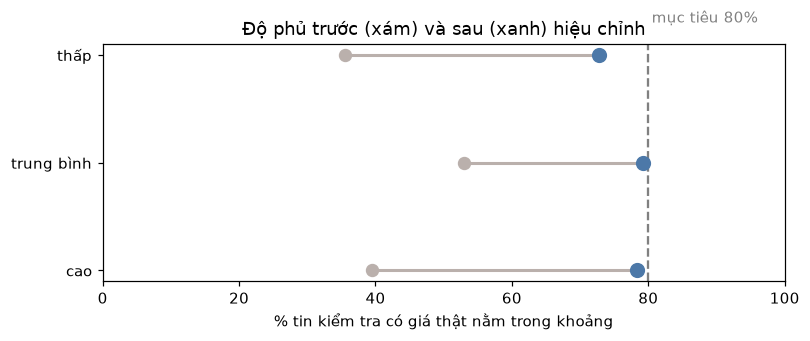

In [26]:
fig, ax = plt.subplots(figsize=(8, 2.8))
for i, (bucket, row) in enumerate(calib.iterrows()):
    ax.plot([row["độ phủ đặt tay (KT, %)"], row["độ phủ mới (KT, %)"]], [i, i], color="#BAB0AC", lw=2)
    ax.scatter(row["độ phủ đặt tay (KT, %)"], i, color="#BAB0AC", s=60, zorder=3)
    ax.scatter(row["độ phủ mới (KT, %)"], i, color="#4C78A8", s=80, zorder=3)
ax.axvline(80, color="gray", ls="--"); ax.text(80.5, 2.3, "mục tiêu 80%", color="gray")
ax.set_yticks(range(len(calib)), calib.index); ax.set_xlim(0, 100)
ax.set_xlabel("% tin kiểm tra có giá thật nằm trong khoảng")
ax.set_title("Độ phủ trước (xám) và sau (xanh) hiệu chỉnh"); plt.show()

## Bước 12 — Lưu mô hình đúng định dạng dịch vụ đang dùng

| Tệp | Nội dung |
|---|---|
| `avm.txt` | cây LightGBM (cắt ở vòng tốt nhất) |
| `avm.meta.joblib` | tập hạng mục + danh sách đặc trưng — **bắt buộc** nạp lại lúc phục vụ |
| `avm.area_stats.parquet` | giá trung vị mỗi m² theo quận + cỡ mẫu |
| `avm.report.json` | độ đo của 4 mô hình, mức đóng góp đặc trưng, kết quả hiệu chỉnh khoảng |

Chép 4 tệp này vào `ml-service/models/` rồi khởi động lại dịch vụ là hệ thống dùng mô hình mới — không phải sửa dòng mã nào.

In [27]:
booster.save_model(str(OUT_DIR / "avm.txt"), num_iteration=booster.best_iteration)
joblib.dump({"categories": cats, "features": FEATURES, "categorical": CATEGORICAL,
             "best_iteration": booster.best_iteration}, OUT_DIR / "avm.meta.joblib")
area_stats.to_parquet(OUT_DIR / "avm.area_stats.parquet", index=False)

def as_report(s):
    return {"n": s["n"], "mdape": s["MdAPE (%)"], "ppe10": s["PPE10 (%)"], "ppe20": s["PPE20 (%)"],
            "rmsle": s["RMSLE"], "median_ae_vnd": s["sai số trung vị (tỷ)"] * 1e9}

report = {
    "trained_at": pd.Timestamp.utcnow().isoformat(),
    "rows_total": int(len(df)), "rows_fit": int(len(fit_df)),
    "rows_valid": int(len(valid_df)), "rows_test": int(len(test_df)),
    "split": "theo thời gian, 15% mới nhất làm tập kiểm tra",
    "train_seconds": round(train_secs, 1), "best_iteration": int(booster.best_iteration),
    "results": {k: as_report(v) for k, v in results.items()},
    "feature_gain_percent": {k: round(v, 2) for k, v in gain_pct.sort_values(ascending=False).items()},
    "interval_calibration": {
        "method": "split conformal theo mức tin cậy", "coverage": 0.8,
        "buckets": {b: {"n_calibration": int(r["n hiệu chỉnh"]), "n_test": int(r["n kiểm tra"]),
                        "old_spread": r["độ rộng đặt tay"],
                        "old_coverage_test": round(r["độ phủ đặt tay (KT, %)"] / 100, 4),
                        "spread_80": round(r["độ rộng conformal q"], 4),
                        "coverage_80_test": round(r["độ phủ mới (KT, %)"] / 100, 4)}
                    for b, r in calib.iterrows()},
    },
}
(OUT_DIR / "avm.report.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
for f in sorted(OUT_DIR.glob("avm.*")):
    print(f"{f.name:<26}{f.stat().st_size / 1024:>10,.0f} KB")

avm.area_stats.parquet            14 KB
avm.meta.joblib                   41 KB
avm.report.json                    2 KB
avm.txt                       39,899 KB


In [28]:
# Trên Colab: tải gói mô hình về máy
import shutil
zip_path = shutil.make_archive("kgs_avm_model", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Không chạy trên Colab — gói mô hình ở", zip_path)

Không chạy trên Colab — gói mô hình ở kgs_avm_model.zip


## Bước 13 — Phục vụ dự đoán (đúng logic `app/predict.py`)

Lúc phục vụ, dịch vụ **nạp mô hình một lần** khi khởi động, rồi với mỗi yêu cầu:

1. Dựng một dòng đặc trưng bằng **đúng hàm `build_features()`** ở bước 5.
2. Ép cột phân loại về **đúng tập hạng mục đã lưu**.
3. Dự đoán log(giá) → đổi ngược ra giá.
4. Tra bảng giá quận → xếp mức tin cậy → lấy độ rộng conformal tương ứng → khoảng giá.
5. Làm tròn tới triệu đồng — hiển thị "4.237.891.523 đồng" là tạo cảm giác chính xác giả.

In [29]:
class AvmModel:
    """Bản thu gọn của app/predict.py: nạp từ thư mục mô hình, trả kết quả như API."""
    def __init__(self, model_dir):
        model_dir = Path(model_dir)
        self.booster = lgb.Booster(model_file=str(model_dir / "avm.txt"))
        self.meta = joblib.load(model_dir / "avm.meta.joblib")
        self.area_stats = pd.read_parquet(model_dir / "avm.area_stats.parquet")
        rep = json.loads((model_dir / "avm.report.json").read_text(encoding="utf-8"))
        cal = rep.get("interval_calibration", {}).get("buckets", {})
        self.spreads = {k: cal.get(k, {}).get("spread_80", v) for k, v in HAND_SPREAD.items()}
        self.report = rep

    def predict(self, payload):
        row = {k: payload.get(k) for k in ["property_type", "province", "district", "ward", "house_direction",
                                          "area", "bedroom_count", "bathroom_count", "floor_count",
                                          "frontage_width", "house_depth", "road_width"]}
        row["published_at"] = payload.get("published_at") or pd.Timestamp.utcnow().isoformat()
        X = to_categorical(build_features(pd.DataFrame([row])), self.meta["categories"])
        log_price = float(self.booster.predict(X[self.meta["features"]])[0])
        price = math.exp(log_price)

        hit = self.area_stats[(self.area_stats.province == norm_province(payload.get("province")))
                              & (self.area_stats.district == norm_district(payload.get("district")))]
        area_n = int(hit.iloc[0]["n"]) if len(hit) else 0
        area_ppm2 = float(hit.iloc[0]["median_ppm2"]) if len(hit) else None

        notes = []
        filled = sum(payload.get(k) is not None for k in FILLED_COLS)
        if area_n == 0:
            confidence = "thấp"; notes.append("Khu vực này chưa từng xuất hiện trong dữ liệu huấn luyện.")
        elif area_n < MIN_AREA_SAMPLE:
            confidence = "thấp"; notes.append(f"Khu vực này chỉ có {area_n} tin trong dữ liệu huấn luyện.")
        elif filled <= 1:
            confidence = "trung bình"; notes.append("Mới khai rất ít thông số — bổ sung để thu hẹp khoảng.")
        elif filled < 3:
            confidence = "trung bình"
        else:
            confidence = "cao"
        q = self.spreads[confidence]
        r = lambda v: float(round(v / 1e6) * 1e6)       # làm tròn tới triệu đồng
        return {"price": r(price), "price_low": r(math.exp(log_price - q)),
                "price_high": r(math.exp(log_price + q)), "interval_calibrated": True,
                "price_per_m2": r(price / max(payload["area"], 1)), "confidence": confidence,
                "area_median_price_per_m2": r(area_ppm2) if area_ppm2 else None,
                "area_sample_size": area_n, "notes": notes}

avm = AvmModel(OUT_DIR)

def show(payload):
    res = avm.predict(payload)
    ty = lambda v: f"{v / 1e9:,.2f} tỷ"
    print(f"{json.dumps(payload, ensure_ascii=False)}\n  → {ty(res['price'])}  (khoảng {ty(res['price_low'])} – "
          f"{ty(res['price_high'])}) · tin cậy: {res['confidence']} · quận có {res['area_sample_size']:,} tin"
          + (f"\n  ! {res['notes'][0]}" if res["notes"] else "") + "\n")

# Cùng một căn, khai nhiều và khai ít thông tin
show({"area": 60, "province": "TP. Hồ Chí Minh", "district": "Quận 8", "property_type": "Nhà",
      "bedroom_count": 3, "bathroom_count": 2, "floor_count": 2, "frontage_width": 4})
show({"area": 60, "province": "TP. Hồ Chí Minh", "district": "Quận 8", "property_type": "Nhà"})
# Một quận ít dữ liệu, và một quận không tồn tại
rare = area_stats[area_stats.n < MIN_AREA_SAMPLE].iloc[0]
show({"area": 100, "province": rare.province, "district": rare.district, "bedroom_count": 3})
show({"area": 60, "province": "TP. Hồ Chí Minh", "district": "Quận 99", "bedroom_count": 3})

{"area": 60, "province": "TP. Hồ Chí Minh", "district": "Quận 8", "property_type": "Nhà", "bedroom_count": 3, "bathroom_count": 2, "floor_count": 2, "frontage_width": 4}
  → 6.41 tỷ  (khoảng 4.63 tỷ – 8.86 tỷ) · tin cậy: cao · quận có 4,182 tin

{"area": 60, "province": "TP. Hồ Chí Minh", "district": "Quận 8", "property_type": "Nhà"}
  → 5.65 tỷ  (khoảng 3.79 tỷ – 8.41 tỷ) · tin cậy: trung bình · quận có 4,182 tin
  ! Mới khai rất ít thông số — bổ sung để thu hẹp khoảng.

{"area": 100, "province": "an giang", "district": "an phu", "bedroom_count": 3}
  → 0.96 tỷ  (khoảng 0.43 tỷ – 2.13 tỷ) · tin cậy: thấp · quận có 1 tin
  ! Khu vực này chỉ có 1 tin trong dữ liệu huấn luyện.

{"area": 60, "province": "TP. Hồ Chí Minh", "district": "Quận 99", "bedroom_count": 3}
  → 1.69 tỷ  (khoảng 0.76 tỷ – 3.74 tỷ) · tin cậy: thấp · quận có 0 tin
  ! Khu vực này chưa từng xuất hiện trong dữ liệu huấn luyện.



## Bước 14 — Tích hợp vào hệ thống KGS

### Kiến trúc: ba tầng, mô hình là một dịch vụ riêng

```
 Trình duyệt (React)            API nghiệp vụ (.NET 8)                 Dịch vụ ML (Python FastAPI)
 ─────────────────────          ───────────────────────────            ───────────────────────────
 /dinh-gia  (trang công khai)   ValuationController                    app/main.py
 Bước 2 đăng tin bán            POST /api/valuation/estimate   ──►     POST /valuation
   (ô "Gợi ý giá")              ValuationService (HttpClient)          app/predict.py  ── models/avm.*
                                http://127.0.0.1:8000, chờ ≤ 5 giây
```

**Vì sao tách mô hình thành dịch vụ Python riêng?**
- **Hệ sinh thái:** LightGBM, pandas, scikit-learn sống ở Python.
- **Vòng đời khác nhau:** mô hình huấn luyện lại theo dữ liệu, API đổi theo tính năng — tách ra thì triển khai độc lập.
- **Hỏng độc lập:** dịch vụ ML chết thì trang tin vẫn chạy, chỉ ẩn ô định giá.

### Luồng hoạt động từ người dùng đến mô hình

```
Người dùng          React (dinh-gia.tsx)        .NET API                         FastAPI (ml-service)
    │ nhập địa chỉ,        │                         │                                  │
    │ diện tích, số phòng  │                         │                                  │
    │ bấm "Định giá" ────► │ useMutation             │                                  │
    │                      │ POST /api/valuation/estimate                               │
    │                      │ {city, district, ward, area, bedrooms…} ─►                 │
    │                      │                         │ 1. Giới hạn tần suất 15 lượt/10 phút│
    │                      │                         │ 2. Cầu dao đang mở? → trả 503 ngay│
    │                      │                         │ 3. Đổi tên trường: city→province, │
    │                      │                         │    bedrooms→bedroom_count…        │
    │                      │                         │ POST /valuation (chờ ≤ 5 giây) ──►│
    │                      │                         │                                  │ 4. Kiểm tra schema (pydantic)
    │                      │                         │                                  │ 5. Chuẩn hoá địa danh
    │                      │                         │                                  │ 6. build_features → LightGBM
    │                      │                         │                                  │ 7. Mức tin cậy + khoảng conformal
    │                      │                         │ ◄── JSON {price, price_low, …} ──│
    │                      │ ◄── 200 ValuationResult │                                  │
    │ ◄── khoảng giá, mức  │                         │                                  │
    │     tin cậy, giá quận│                         │                                  │
```

**Khi có sự cố** — nguyên tắc: định giá là thứ *có thì tốt*, không bao giờ được chặn việc đăng tin:

| Tình huống | .NET xử lý | Người dùng thấy |
|---|---|---|
| Dịch vụ ML chưa chạy / sập / quá 5 giây | bật **cầu dao 30 giây**: các lần gọi trong 30 giây trả ngay, không chờ | "Dịch vụ định giá chưa sẵn sàng" (503); trang đăng tin ẩn ô gợi ý giá |
| Mô hình chưa nạp | FastAPI trả 503 | như trên |
| Dữ liệu gửi sai (diện tích ngoài 1–10.000 m²…) | .NET chặn 400; dịch vụ ML còn một lớp kiểm tra nữa (422) | thông báo nhập lại |
| Gọi quá 15 lần / 10 phút | trả 429 | thông báo thử lại sau |

Hai điểm dùng mô hình trong giao diện: **trang /dinh-gia** (công khai, không cần đăng nhập) và **ô "Gợi ý giá" ở bước 2 khi đăng tin bán**. Cả hai gọi cùng một endpoint.

Ô dưới dựng lại dịch vụ FastAPI với **đúng hợp đồng dữ liệu** của `app/schemas.py`, rồi gọi nó bằng **đúng JSON mà `ValuationService.cs` gửi sang** — để thấy tận mắt từng bước của luồng trên.

In [30]:
from typing import Optional
from datetime import datetime
from fastapi import FastAPI, HTTPException
from fastapi.testclient import TestClient
from pydantic import BaseModel, Field

class ValuationRequest(BaseModel):                 # app/schemas.py
    area: float = Field(gt=0, le=10_000)
    province: str = Field(min_length=1, max_length=100)
    district: str = Field(min_length=1, max_length=100)
    ward: Optional[str] = None
    property_type: Optional[str] = None
    house_direction: Optional[str] = None
    bedroom_count: Optional[float] = Field(default=None, ge=0, le=50)
    bathroom_count: Optional[float] = Field(default=None, ge=0, le=50)
    floor_count: Optional[float] = Field(default=None, ge=0, le=100)
    frontage_width: Optional[float] = Field(default=None, ge=0, le=200)
    house_depth: Optional[float] = None
    road_width: Optional[float] = None
    published_at: Optional[datetime] = None

app = FastAPI(title="KGS · Dịch vụ định giá (mô phỏng trong notebook)")
state = {"model": avm}

@app.get("/health")
def health():
    return {"status": "ok" if state["model"] else "chưa có mô hình", "model_loaded": state["model"] is not None}

@app.get("/model-info")
def model_info():
    g = state["model"].report["results"]["Gradient Boosting (LightGBM)"]
    return {"loaded": True, "mdape": round(g["mdape"], 2), "ppe10": round(g["ppe10"], 1),
            "best_iteration": state["model"].report["best_iteration"]}

@app.post("/valuation")
def valuation(req: ValuationRequest):
    if state["model"] is None:
        raise HTTPException(503, "Mô hình định giá chưa sẵn sàng.")
    return state["model"].predict(req.model_dump())

ml = TestClient(app)
print("GET /health     →", ml.get("/health").json())
print("GET /model-info →", ml.get("/model-info").json())

GET /health     → {'status': 'ok', 'model_loaded': True}
GET /model-info → {'loaded': True, 'mdape': 17.49, 'ppe10': 31.0, 'best_iteration': 2999}


In [31]:
# ---- Mô phỏng phía .NET (ValuationService.cs): nhận yêu cầu từ trình duyệt, đổi tên trường, gọi dịch vụ ML ----
def dotnet_estimate(browser_body, ml_client):
    """Trả (mã HTTP, body) như ValuationController.Estimate trả về cho trình duyệt."""
    if not 1 <= browser_body["area"] <= 10_000:   # [Range(1, 10_000)] trên ValuationRequest (.NET)
        return 400, {"errors": {"Area": ["The field Area must be between 1 and 10000."]}}
    payload = {                                   # MlValuationRequest — gửi NGUYÊN VĂN địa danh,
        "area": browser_body["area"],             # việc chuẩn hoá để dịch vụ Python làm (một nơi duy nhất)
        "province": browser_body["city"], "district": browser_body["district"],
        "ward": browser_body.get("ward"), "property_type": browser_body.get("propertyType"),
        "house_direction": browser_body.get("houseDirection"),
        "bedroom_count": browser_body.get("bedrooms"), "bathroom_count": browser_body.get("bathrooms"),
        "floor_count": browser_body.get("floors"), "frontage_width": browser_body.get("frontage"),
    }
    print("  .NET → ML  POST /valuation", json.dumps(payload, ensure_ascii=False))
    try:
        res = ml_client.post("/valuation", json=payload)
    except Exception as exc:                      # mất kết nối / quá 5 giây → bật cầu dao 30 giây
        print("  .NET: không gọi được dịch vụ ML:", type(exc).__name__)
        return 503, {"message": "Dịch vụ định giá hiện chưa sẵn sàng."}
    if res.status_code != 200:
        print(f"  .NET: dịch vụ ML trả {res.status_code} → quy về 'chưa có giá tham khảo'")
        return 503, {"message": "Dịch vụ định giá hiện chưa sẵn sàng."}
    b = res.json()
    return 200, {"price": b["price"], "priceLow": b["price_low"], "priceHigh": b["price_high"],
                 "pricePerM2": b["price_per_m2"], "confidence": b["confidence"],
                 "areaMedianPricePerM2": b["area_median_price_per_m2"],
                 "areaSampleSize": b["area_sample_size"], "notes": b["notes"]}

# 1) Người dùng trên trang /dinh-gia bấm "Định giá" — body React gửi lên .NET
browser_body = {"city": "TP. Hồ Chí Minh", "district": "Quận 8", "ward": None, "area": 60,
                "propertyType": "Nhà", "bedrooms": 3, "bathrooms": 2, "floors": 2, "frontage": 4}
print("Trình duyệt → .NET  POST /api/valuation/estimate", json.dumps(browser_body, ensure_ascii=False))
status, body = dotnet_estimate(browser_body, ml)
print(f"Trình duyệt ← .NET  {status}", json.dumps(body, ensure_ascii=False, indent=1))

Trình duyệt → .NET  POST /api/valuation/estimate {"city": "TP. Hồ Chí Minh", "district": "Quận 8", "ward": null, "area": 60, "propertyType": "Nhà", "bedrooms": 3, "bathrooms": 2, "floors": 2, "frontage": 4}
  .NET → ML  POST /valuation {"area": 60, "province": "TP. Hồ Chí Minh", "district": "Quận 8", "ward": null, "property_type": "Nhà", "house_direction": null, "bedroom_count": 3, "bathroom_count": 2, "floor_count": 2, "frontage_width": 4}
Trình duyệt ← .NET  200 {
 "price": 6405000000.0,
 "priceLow": 4631000000.0,
 "priceHigh": 8860000000.0,
 "pricePerM2": 107000000.0,
 "confidence": "cao",
 "areaMedianPricePerM2": 92000000.0,
 "areaSampleSize": 4182,
 "notes": []
}


In [32]:
# 2) Dữ liệu sai bị chặn ở HAI lớp: .NET kiểm tra trước (400), dịch vụ ML kiểm tra lại bằng pydantic (422)
bad = dict(browser_body, area=0)
print("Diện tích = 0:")
print("  qua .NET (lớp 1)          →", dotnet_estimate(bad, ml))
print("  gọi thẳng FastAPI (lớp 2) →", ml.post("/valuation", json={"area": 0, "province": "x", "district": "y"}).status_code)

# 3) Mô hình chưa được nạp (vd. vừa triển khai, chưa chép tệp mô hình)
state["model"] = None
print("\nMô hình chưa nạp:")
print("  qua .NET →", dotnet_estimate(browser_body, ml))
state["model"] = avm

Diện tích = 0:
  qua .NET (lớp 1)          → (400, {'errors': {'Area': ['The field Area must be between 1 and 10000.']}})
  gọi thẳng FastAPI (lớp 2) → 422

Mô hình chưa nạp:
  .NET → ML  POST /valuation {"area": 60, "province": "TP. Hồ Chí Minh", "district": "Quận 8", "ward": null, "property_type": "Nhà", "house_direction": null, "bedroom_count": 3, "bathroom_count": 2, "floor_count": 2, "frontage_width": 4}
  .NET: dịch vụ ML trả 503 → quy về 'chưa có giá tham khảo'
  qua .NET → (503, {'message': 'Dịch vụ định giá hiện chưa sẵn sàng.'})


## Tổng kết — kết quả từng bước của lần chạy này

In [33]:
g = results["Gradient Boosting (LightGBM)"]
summary = pd.DataFrame([
    ("1. Tải dữ liệu", f"{funnel.iloc[0]['còn lại']:,} dòng thô từ {N_SHARDS} shard"),
    ("3. Làm sạch + bỏ trùng", f"còn {len(df):,} tin bán"),
    ("6. Chia theo thời gian", f"học {len(fit_df):,} · kiểm định {len(valid_df):,} · kiểm tra {len(test_df):,}"),
    ("7. Mô hình nền tốt nhất", f"Ridge, MdAPE {results['Nền 3 · Hồi quy tuyến tính (Ridge)']['MdAPE (%)']:.1f}%"),
    ("8. LightGBM", f"{booster.best_iteration} vòng, {train_secs:.0f} giây"),
    ("9. Đánh giá trên tập kiểm tra", f"MdAPE {g['MdAPE (%)']:.1f}% · PPE10 {g['PPE10 (%)']:.1f}% · PPE20 {g['PPE20 (%)']:.1f}%"),
    ("10. Đặc trưng mạnh nhất", f"{gain_pct.idxmax()} ({gain_pct.max():.1f}%)"),
    ("11. Hiệu chỉnh khoảng", "độ phủ " + " · ".join(f"{b} {r['độ phủ mới (KT, %)']:.1f}%" for b, r in calib.iterrows())),
    ("12. Lưu mô hình", f"{len(list(OUT_DIR.glob('avm.*')))} tệp trong {OUT_DIR}/"),
], columns=["bước", "kết quả"])
summary

,bước,kết quả
0,1. Tải dữ liệu,"1,050,225 dòng thô từ 3 shard"
1,3. Làm sạch + bỏ trùng,"còn 637,598 tin bán"
2,6. Chia theo thời gian,"học 487,763 · kiểm định 54,195 · kiểm tra 95,640"
3,7. Mô hình nền tốt nhất,"Ridge, MdAPE 26.8%"
4,8. LightGBM,"2999 vòng, 107 giây"
5,9. Đánh giá trên tập kiểm tra,MdAPE 17.5% · PPE10 31.0% · PPE20 55.4%
6,10. Đặc trưng mạnh nhất,district (40.3%)
7,11. Hiệu chỉnh khoảng,độ phủ cao 78.4% · trung bình 79.2% · thấp 72.8%
8,12. Lưu mô hình,4 tệp trong kgs_models/
